# OpenVLA Demo

Loads `openvla/openvla-7b` and runs inference on an image and a language instruction.

Before running: set **Runtime → Change runtime type → Runtime version** to an older
dated release (not "Latest"), and set **Hardware accelerator** to **T4 GPU**. The next
cell verifies this.

## 1. Mount Google Drive for persistent caching

Mounts Google Drive and points Hugging Face's cache there, so model weights persist
across Colab sessions.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import os
CACHE_DIR = '/content/drive/MyDrive/VLA_Demo_Cache'
os.makedirs(CACHE_DIR, exist_ok=True)
os.environ['HF_HOME'] = os.path.join(CACHE_DIR, 'huggingface')


Mounted at /content/drive


### Verify the runtime version

Checks the Python version. If it warns, change the runtime version before continuing.

In [2]:
!python --version
import sys
major, minor = sys.version_info[:2]
if (major, minor) >= (3, 13):
    print("\nWARNING: still on Python 3.13+ - the original validated tokenizers==0.19.1 "
          "will NOT install. Go to Runtime > Change runtime type > Runtime version and "
          "pick an older dated version (not 'Latest'), then reconnect and re-run from the top.")
else:
    print("\nOK - Python <= 3.12, the original validated versions below should install cleanly.")


Python 3.11.13

OK - Python <= 3.12, the original validated versions below should install cleanly.


## 2. Install dependencies

Installs the specific `torch`, `torchvision`, `transformers`, `tokenizers`, `timm`, and
`numpy` versions required for `openvla-7b` to load and run correctly on this runtime.

In [ ]:
!pip install -q "torch==2.2.0" "torchvision==0.17.0" "transformers==4.44.2" "tokenizers==0.19.1" "timm==0.9.10" accelerate bitsandbytes
!pip install -q --force-reinstall --no-deps --no-cache-dir "numpy==1.26.4"

## 3. Load openvla-7b

Loads the processor and model. `USE_4BIT` controls whether to use 4-bit quantization
(set to `True` if VRAM is insufficient). Uses `attn_implementation="sdpa"`, disables the
TensorFlow/Flax backends, and falls back to CPU automatically if no GPU is available.
Also verifies the installed `timm` version before importing, reinstalling it if
needed.

In [3]:
import importlib.metadata, subprocess, sys

_timm_version = importlib.metadata.version("timm")
if _timm_version != "0.9.10":
    print(f"timm {_timm_version} found (need exactly 0.9.10) - reinstalling...")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "timm==0.9.10"], check=True)
    print("timm fixed. Continuing.")

import os
os.environ["USE_TF"] = "0"
os.environ["USE_FLAX"] = "0"

from transformers import AutoModelForVision2Seq, AutoProcessor, BitsAndBytesConfig
import torch

USE_4BIT = False  # flip to True only if you hit a VRAM error on the T4

# Falls back to CPU automatically if no GPU is actually available this session
# (e.g. Colab's free-tier GPU quota ran out even though T4 was selected) - slower,
# but lets you keep testing instead of hard-crashing on `.to("cuda:0")`.
DEVICE = "cuda:0" if torch.cuda.is_available() else "cpu"
if DEVICE == "cpu":
    print("WARNING: no GPU available this session (quota exhausted or CPU-only "
          "runtime) - falling back to CPU. Inference will be much slower (expect "
          "tens of seconds per image instead of ~1s), but this should still work.")

processor = AutoProcessor.from_pretrained("openvla/openvla-7b", trust_remote_code=True)

if USE_4BIT:
    bnb_config = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_compute_dtype=torch.bfloat16)
    vla = AutoModelForVision2Seq.from_pretrained(
        "openvla/openvla-7b",
        quantization_config=bnb_config,
        attn_implementation="sdpa",
        trust_remote_code=True,
    )
else:
    vla = AutoModelForVision2Seq.from_pretrained(
        "openvla/openvla-7b",
        torch_dtype=torch.bfloat16,
        low_cpu_mem_usage=True,
        attn_implementation="sdpa",
        trust_remote_code=True,
    ).to(DEVICE)


timm 1.0.17 found (need exactly 0.9.10) - reinstalling...
timm fixed. Continuing.


/usr/local/lib/python3.11/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(
Using a slow image processor as `use_fast` is unset and a slow processor was saved with this model. `use_fast=True` will be the default behavior in v4.52, even if the model was saved with a slow processor. This will result in minor differences in outputs. You'll still be able to use a slow processor with `use_fast=False`.


Loading checkpoint shards:   0%|          | 0/3 [00:00<?, ?it/s]

## 4. Helper functions: run inference and visualize

`run_openvla` sends an image and instruction to the model and returns the predicted
7-DoF action. `visualize_action` plots the predicted direction as a fixed-length arrow
from a labeled reference point; the reference point is the image's center, not a
detected object location, and the arrow's length does not indicate magnitude.

In [4]:
from google.colab import files
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

ACTION_DIM_LABELS = ['x', 'y', 'z', 'yaw', 'pitch', 'roll', 'grasp']

def run_openvla(image, instruction, unnorm_key="bridge_orig"):
    """image: a PIL.Image. Returns the predicted 7-DoF action as a numpy array."""
    prompt = f"In: What action should the robot take to {instruction}?\nOut:"
    inputs = processor(prompt, image).to(vla.device, dtype=torch.bfloat16)
    action = vla.predict_action(**inputs, unnorm_key=unnorm_key, do_sample=False)
    return np.array(action)

def visualize_action(image, action, title=""):
    """Draws the predicted step as a fixed-length arrow from a labeled reference point.
    The reference point is the image's geometric center - not a detected gripper
    position or grasp target, see the markdown note above - and the arrow direction is
    normalized to a fixed, always-visible length, because the model's raw deltas are
    too small to show at any single fixed pixel scale: a previous version multiplied
    the raw delta by a flat constant, which worked out to a few tenths of a screen pixel
    once matplotlib downscaled a 640x480 (or larger) photo into the figure - invisible
    regardless of the constant chosen. Normalizing to direction-only avoids this: the
    arrow is always a clearly visible fixed fraction of the image size, in any photo
    resolution, and never claims a magnitude it isn't drawn to scale for anyway."""
    fig, ax = plt.subplots(figsize=(5, 5))
    ax.imshow(image)
    w, h = image.size
    cx, cy = w / 2, h / 2
    dx_raw, dy_raw = float(action[0]), -float(action[1])
    norm = (dx_raw ** 2 + dy_raw ** 2) ** 0.5
    arrow_len = 0.22 * min(w, h)
    if norm > 1e-6:
        dx, dy = dx_raw / norm * arrow_len, dy_raw / norm * arrow_len
        ax.arrow(cx, cy, dx, dy, head_width=0.04 * min(w, h), width=0.012 * min(w, h),
                 color='red', length_includes_head=True, zorder=3)
    ax.plot(cx, cy, 'o', color='yellow', markersize=12, markeredgecolor='black',
            markeredgewidth=1.5, zorder=4)
    ax.annotate("reference point (not a detected target)", (cx, cy), xytext=(12, 12),
                textcoords='offset points', fontsize=11, color='black',
                bbox=dict(boxstyle='round,pad=0.3', fc='yellow', ec='black', alpha=0.9),
                zorder=5)
    ax.set_title(title)
    ax.axis('off')
    plt.show()
    print({k: round(float(v), 3) for k, v in zip(ACTION_DIM_LABELS, action)})


## 5. Pre-loaded comparison pairs

Runs a fixed set of four (image, instruction) pairs through the model, the same ones
used in `Octo_Demo.ipynb`.

Pair 3's instruction ("pick up the fruit") tests semantic generalization; the
predicted-direction arrow does not indicate which object was identified as the
target.

=== Instruction: 'pick up the spatula'  —  baseline: one clear, unambiguous target ===


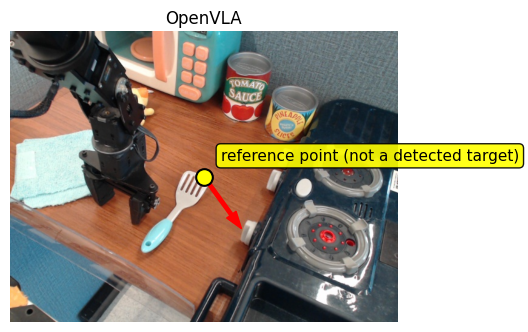

{'x': 0.004, 'y': -0.005, 'z': 0.008, 'yaw': -0.006, 'pitch': -0.027, 'roll': -0.029, 'grasp': 0.996}
=== Instruction: 'pick up the spoon, not the pot'  —  distractor / language grounding ===


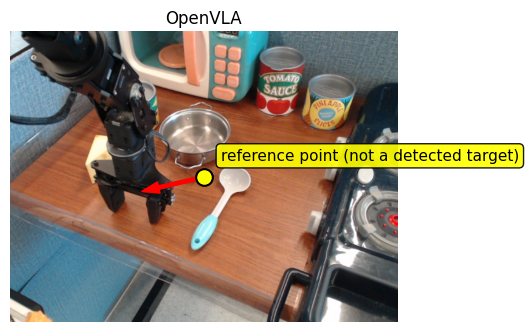

{'x': -0.0, 'y': -0.0, 'z': -0.001, 'yaw': -0.001, 'pitch': 0.005, 'roll': -0.0, 'grasp': 0.996}
=== Instruction: 'pick up the fruit'  —  semantic generalization (RT-2-style) ===


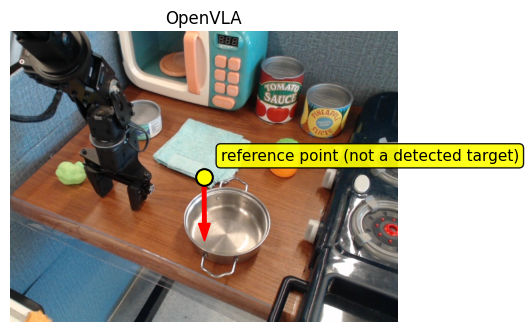

{'x': 0.0, 'y': -0.002, 'z': 0.0, 'yaw': -0.012, 'pitch': 0.004, 'roll': 0.003, 'grasp': 0.996}
=== Instruction: 'pick up the spatula'  —  scene robustness: SAME instruction as pair 1, a cluttered scene instead ===


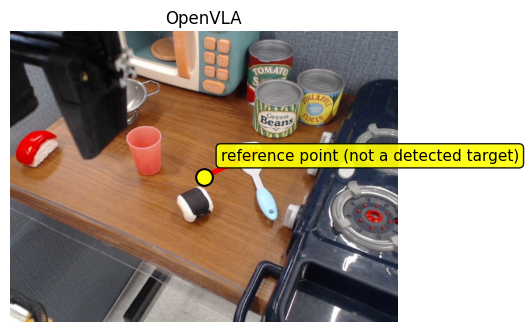

{'x': 0.0, 'y': 0.0, 'z': -0.003, 'yaw': 0.002, 'pitch': 0.007, 'roll': -0.016, 'grasp': 0.996}

All 4 results identical? False


In [5]:
TEST_PAIRS = [
    # All 4 images are real BridgeData V2 frames (same toy-kitchen environment
    # Octo's own official example uses) - see test_images/README.md for what's in each.
    ("/content/drive/MyDrive/VLA_Demo_Cache/test_images/pair1_cup.jpg",
     "pick up the spatula", "baseline: one clear, unambiguous target"),
    ("/content/drive/MyDrive/VLA_Demo_Cache/test_images/pair2_fork_cup.jpg",
     "pick up the spoon, not the pot", "distractor / language grounding"),
    ("/content/drive/MyDrive/VLA_Demo_Cache/test_images/pair3_fruit.jpg",
     "pick up the fruit", "semantic generalization (RT-2-style)"),
    ("/content/drive/MyDrive/VLA_Demo_Cache/test_images/pair4_cluttered.jpg",
     "pick up the spatula", "scene robustness: SAME instruction as pair 1, a cluttered scene instead"),
]

results = []
for image_path, instruction, what_it_tests in TEST_PAIRS:
    image = Image.open(image_path).convert("RGB")
    print(f"=== Instruction: {instruction!r}  —  {what_it_tests} ===")
    action = run_openvla(image, instruction)
    visualize_action(image, action, title="OpenVLA")
    results.append(action)

import numpy as np
all_identical = all(np.allclose(results[0], r, atol=1e-6) for r in results[1:])
print()
print("All 4 results identical?", all_identical)
if all_identical:
    print("If this is True, something is wrong with the environment - re-check the "
          "install cell versions above before trusting these results.")


## 6. Try it yourself — upload a photo and type an instruction

Uploads a photo, prompts for an instruction, and runs the model on it.

Upload an image (jpg/png):


Saving extra2_pot_lid.jpg to extra2_pot_lid.jpg
Type an instruction (e.g. 'pick up the spatula'): pot lid


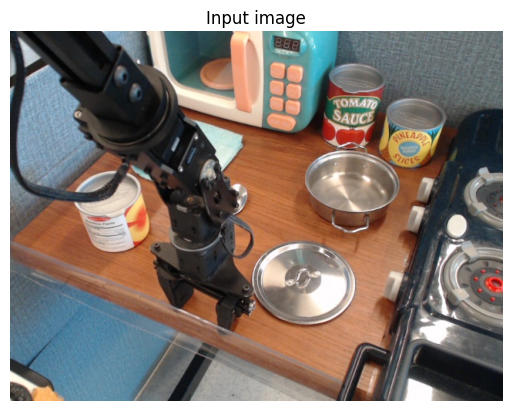

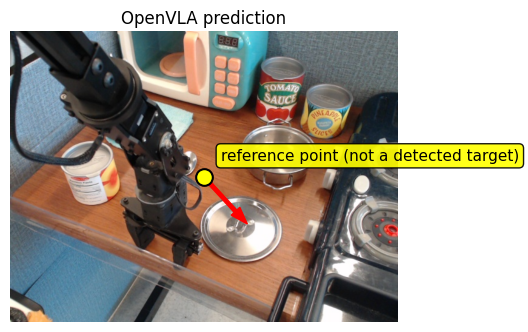

{'x': 0.005, 'y': -0.006, 'z': 0.001, 'yaw': 0.005, 'pitch': 0.001, 'roll': 0.011, 'grasp': 0.996}


In [6]:
from google.colab import files
from PIL import Image

print("Upload an image (jpg/png):")
uploaded = files.upload()
IMAGE_PATH = list(uploaded.keys())[0]

INSTRUCTION = input("Type an instruction (e.g. 'pick up the spatula'): ").strip()
if not INSTRUCTION:
    INSTRUCTION = "pick up the object"

image = Image.open(IMAGE_PATH).convert("RGB")
plt.imshow(image); plt.axis('off'); plt.title("Input image"); plt.show()

action = run_openvla(image, INSTRUCTION)
visualize_action(image, action, title="OpenVLA prediction")
